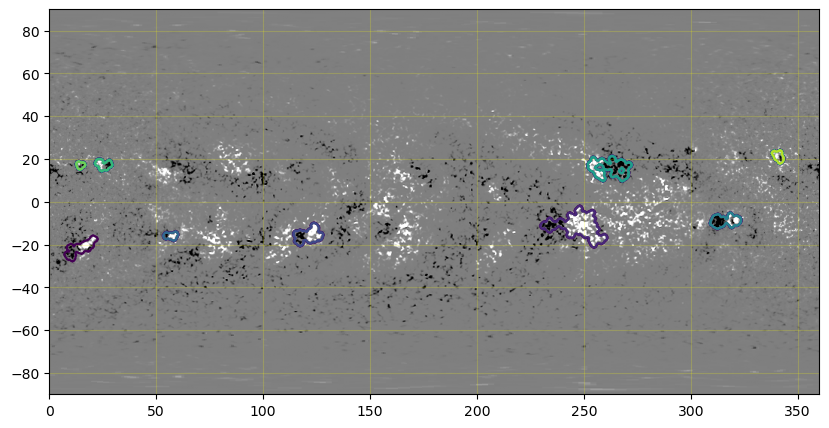

In [18]:
import os.path
%reload_ext autoreload
%autoreload 2
import autotab.detection as ad
import matplotlib.pyplot as plt
import numpy as np
ardata = ad.ARdata()

ardata.load_data("/Users/bjha/Data/AFT/AFTmapv2/2014/10/AFTmap_20141015_0000.h5", data_type="aftmap")
aftdata = ardata.get_arinfo()
im = aftdata.image
fig, ax1 = plt.subplots(1,1, figsize=(10,5), sharey = "row")
mask = aftdata.mask
ax1.imshow(im, vmax=100, vmin=-100, origin="lower", cmap="gray", extent=(0,360,-90,90))
# ax1.imshow(mask)
# labels =label(mask, connectivity=2)
ax1.contour(mask, levels=np.unique(mask), extent=(0,360,-90,90))
ax1.grid(alpha=0.2, color="yellow")

In [8]:
aftdata.th

150.0

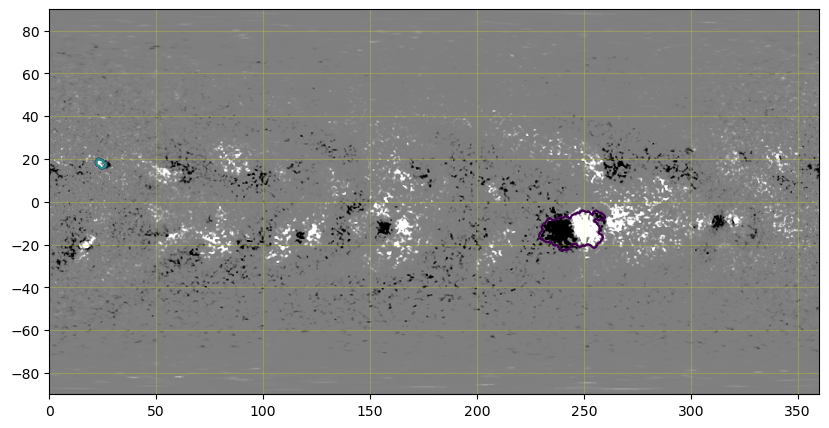

In [14]:
ardata.load_data("/Volumes/SwRI_SSD/Data/AFT/AFTfarmap/GONG/GONG_f03/2014/10/AFTmap_20141014_1600.h5", data_type="aftmap")
aftdata = ardata.get_arinfo()
im = aftdata.image
fig, ax1 = plt.subplots(1,1, figsize=(10,5), sharey = "row")
mask = aftdata.mask
ax1.imshow(im, vmax=100, vmin=-100, origin="lower", cmap="gray", extent=(0,360,-90,90))
# ax1.imshow(mask)
# labels =label(mask, connectivity=2)
ax1.contour(mask, levels=np.unique(mask), extent=(0,360,-90,90))
ax1.grid(alpha=0.2, color="yellow")

In [6]:
aftdata.th

292.307565

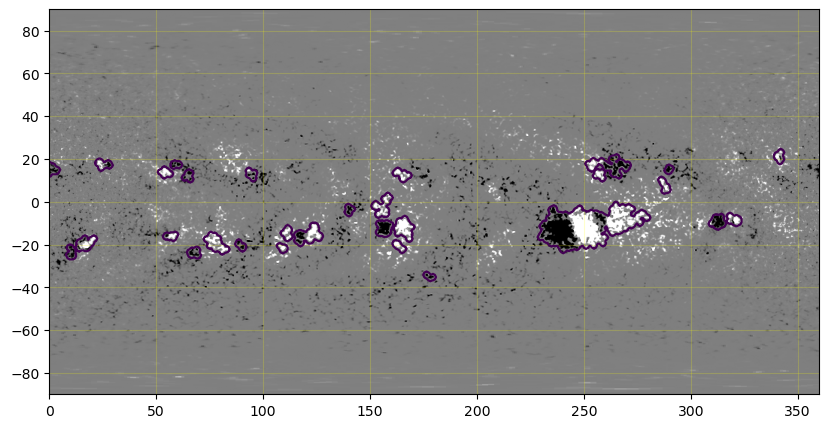

In [16]:
from skimage.morphology import binary_closing, area_opening, binary_dilation, disk
import scipy.ndimage as nd
mask = np.where(np.abs(aftdata.image) > 150, 1, 0)
maskc = binary_closing(mask, disk(4))
maskc = area_opening(maskc, 5)
maskc = nd.binary_fill_holes(maskc)
maskc = area_opening(maskc, 20)
maskc = binary_closing(maskc, disk(4))
mask2 = binary_dilation(maskc, disk(3))

fig, ax1 = plt.subplots(1,1, figsize=(10,5), sharey = "row")
ax1.imshow(aftdata.image, vmax=100, vmin=-100, origin="lower", cmap="gray", extent=(0,360,-90,90))
# ax1.imshow(mask)
# labels =label(mask, connectivity=2)
ax1.contour(mask2, levels=np.unique(mask), extent=(0,360,-90,90))
ax1.grid(alpha=0.2, color="yellow")

     Type of files : aftmap    
       File Format : H5        
   Number of files : 11601     
 Number of threads : 10        
2010 06
2010 06-01T08:00:00.00: For 1 files 0.023 minutes taken.
2010 06-01T16:00:00.00: For 2 files 0.046 minutes taken.
2010 06-02T00:00:00.00: For 3 files 0.070 minutes taken.


KeyboardInterrupt: 

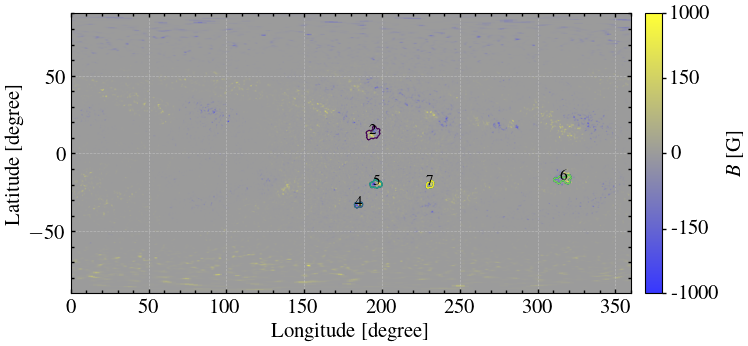

In [5]:
%reload_ext autoreload
%autoreload 2
import autotab.detection as ad
from autotab.tracking import TrackAR

ardata = ad.ARdata()
ardata.load_data("/sol/d0/SFT/AFT304/aftmap/", data_type="aftmap", nthreads=10)
# ardata.load_data("/Users/bjha/Documents/test_track", data_type="aftmap", nthreads=10)
ars = ardata.get_ARs()
tars = TrackAR(ars)
tardata = tars.get_trackedinfo(save_output="/sol/d0/SFT/AFT304/armap/", saveimage=True)
tardata.to_json("data/ardata_304_tracked_2014_v1.1.json")
tardata.to_csv("data/ardata_304_tracked_2014_v1.1.csv")

In [23]:
tardata.to_json("data/ardata_304_tracked_2014.json")
tardata.to_csv("data/ardata_304_tracked_2014.csv")
# from autotab.datatype import datatype
# datatype(tardata).to_json("data/ardata_304_tracked_2014.json")

In [2]:
%reload_ext autoreload
%autoreload 2
from autotab.datatype import datatype
dd = datatype(tardata.data)

In [5]:
dd.to_yaml("data/ardata_304_tracked_2014.yaml")

In [52]:
tardata.to_json("data/ardata_304_tracked_2014.json")
tardata.to_csv("data/ardata_304_tracked_2014.csv")

In [6]:
# dd.data

In [18]:
ars

<generator object ARdata.get_ARs at 0x13f26b4c0>

In [198]:
para

KeyError: 0

In [200]:
def yy(i):
    for ii in range(i):
        yield ii**2

In [201]:
a = yy(10)

In [32]:
int("3")

3

In [4]:
def y():
    for i in range(10):
        yield i

In [8]:
a=y()

In [14]:
reverse(a)

NameError: name 'reverse' is not defined

In [3]:
from autotab.aftmap import AFTmap

==============================AFTmap_20200224_0600.h5==============================

AFT_VER1  : HMI_Baseline4                  - Name of AFT Version           
AUTHOR    : Lisa A. Upton & Bibhuti K Jha  - Name of creator               
CAR_ROT   : 2227                           - Carrington Rotation of last data
CRLN_OBS  : 76.5032729283                  - Carrington Longitude (l0) of last data
CRLNGEDG  : 0.0                            - WSA SPEC: Carr-long of leading edge
CRLT_OBS  : -7.11999082565                 - Carrington Latitide (b0) of last data
CRROTEDG  : 2227                           - WSA SPEC: Carr-rot of leading edge
DATE      : 2023-08-03T11:41:53.00         - Creation date of AFT Map      
FARSIDE1  : None                           - Has Farside Data Been Added   
FARSIDE2  : N/A                            - Which Farside Data was Added  
GRID      : 0.351563                       - Uniform grid res: del(lat)=del(lng)
LAST_MAP  : hmi.m_720s.20200224_060000_TAI.3.mag

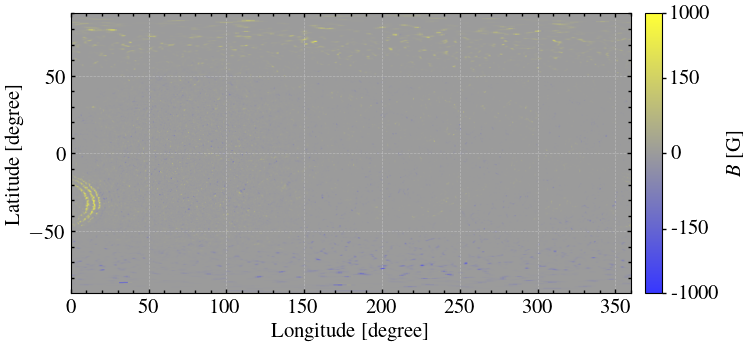

In [55]:
a = AFTmap("/Users/bjha/apps/aditya/AFTmap_20200224_0600.h5")
print(a)

In [52]:
import h5py as h5
file = "/Users/bjha/apps/aditya/AFTmap_20200225_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]
    hgmap =fl["maps/magmap"][()]
    mask = fl["maps/mask"][()]

In [29]:
fl =h5.File(file)

In [31]:
fl["maps"].keys()

<KeysViewHDF5 ['aftmap', 'magmap', 'mask', 'vlat', 'vlon']>

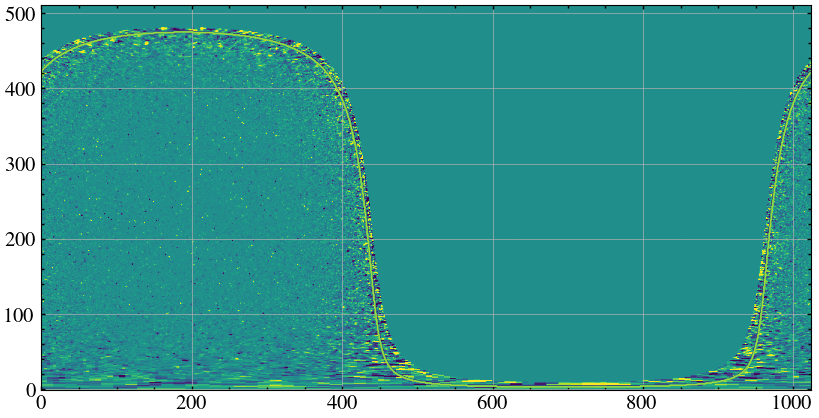

In [53]:
plt.figure(figsize=(10,5))
plt.imshow(hgmap, vmax=100, vmin=-100, origin="lower")
plt.contour(mask)
